<center><h1>Peng_Yu-Hsuan_HW5</h1></center>
<br>
<br>

Name: Yu-Hsuan Peng
<br>
Github Username: Vincent2k0624
<br>
USC ID: 1889-9849-82

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Acute Inflammations Data Set

In [2]:
columns = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra", "bladder_inflammation", "nephritis"]

acute_data = pd.read_csv("diagnosis.data", sep = "\t", header = None, names = columns, encoding = "utf-16", decimal = ",")
display(acute_data.head())
print("Data shape :", acute_data.shape)

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


Data shape : (120, 8)


### (b) Build a decision tree

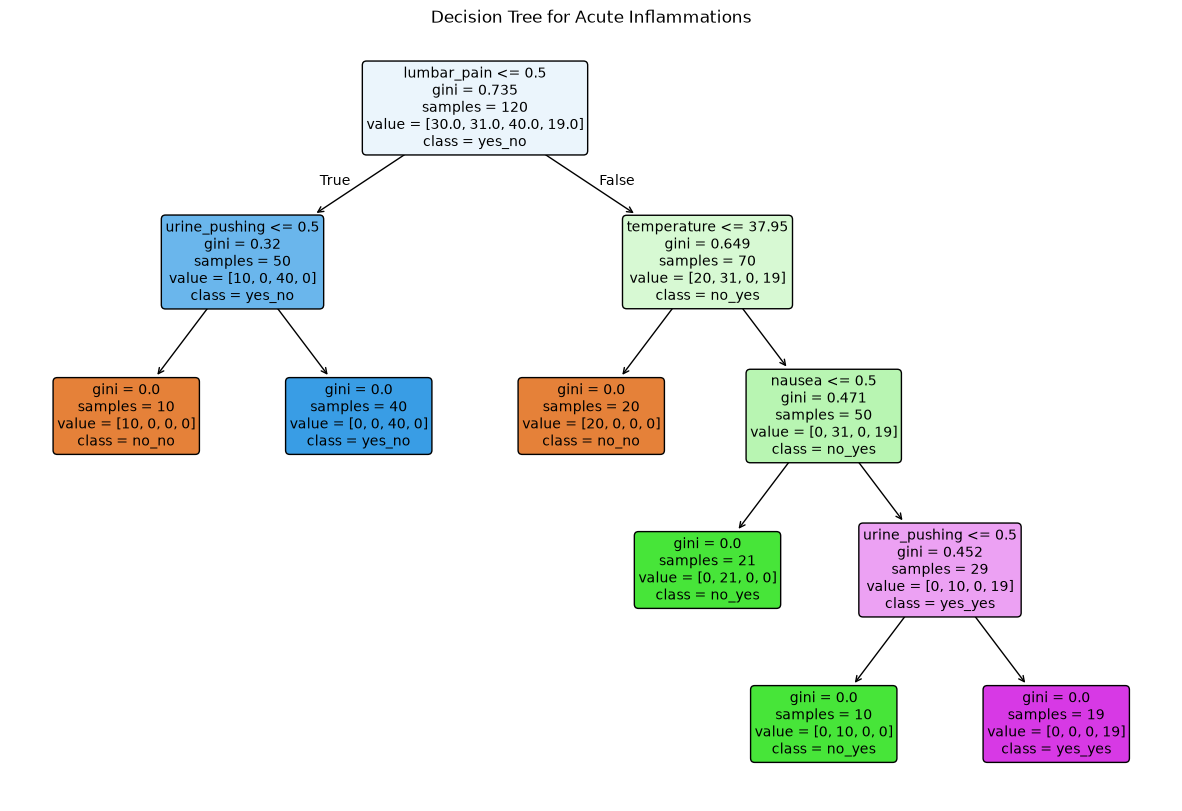

In [3]:
X = acute_data.iloc[:, : 6].copy()

for column in X.columns[1 :]:
    X[column] = X[column].map({"no" : 0, "yes" : 1})

y = (acute_data["bladder_inflammation"] + "_" + acute_data["nephritis"])

decision_tree = DecisionTreeClassifier(random_state = 42)
decision_tree.fit(X, y)

plt.figure(figsize = (15, 10))
plot_tree(decision_tree, feature_names = X.columns.tolist(), class_names = decision_tree.classes_.tolist(), filled = True, rounded = True, fontsize = 10)
plt.title("Decision Tree for Acute Inflammations")
plt.show()

### (c) Convert the decision rules

In [4]:
def tree_to_pseudo(model,feature_names):
    tree = model.tree_

    def recurse(node, depth):
        indent = " " * depth

        if tree.children_left[node] != -1:
            feature = feature_names[tree.feature[node]]
            threshold = tree.threshold[node]

            print(f"{indent}IF {feature} <= {threshold:.2f} THEN")
            recurse(tree.children_left[node], depth + 1)

            print(f"{indent}ELSE")
            recurse(tree.children_right[node], depth + 1)

        else:
            label = model.classes_[np.argmax(tree.value[node][0])]
            print(f"{indent}RETURN {label}")

    recurse(0, 0)

tree_to_pseudo(decision_tree, X.columns.tolist())

IF lumbar_pain <= 0.50 THEN
 IF urine_pushing <= 0.50 THEN
  RETURN no_no
 ELSE
  RETURN yes_no
ELSE
 IF temperature <= 37.95 THEN
  RETURN no_no
 ELSE
  IF nausea <= 0.50 THEN
   RETURN no_yes
  ELSE
   IF urine_pushing <= 0.50 THEN
    RETURN no_yes
   ELSE
    RETURN yes_yes


### (d) Cost-complexity pruning

In [5]:
path = decision_tree.cost_complexity_pruning_path(X, y)

cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
results = []

for alpha in np.unique(path.ccp_alphas):
    model = DecisionTreeClassifier(random_state = 42, ccp_alpha = alpha)

    scores = cross_val_score(model, X, y, cv=cv)
    model.fit(X, y)

    results.append({"alpha" : alpha, "CV accuracy" : scores.mean(), "Leaves" : model.get_n_leaves(), "Depth": model.get_depth()})

pruning_results = pd.DataFrame(results)
display(pruning_results)

best_score = pruning_results["CV accuracy"].max()

best_alpha = pruning_results.loc[np.isclose(pruning_results["CV accuracy"], best_score), "alpha"].max()

print("Selected alpha:", best_alpha)

,alpha,CV accuracy,Leaves,Depth
0,0.000000,0.991667,6,4
1,0.098167,0.858333,4,2
2,0.133333,0.758333,3,2
3,0.182000,0.666667,2,1
4,0.222917,0.483333,1,0


Selected alpha: 0.0


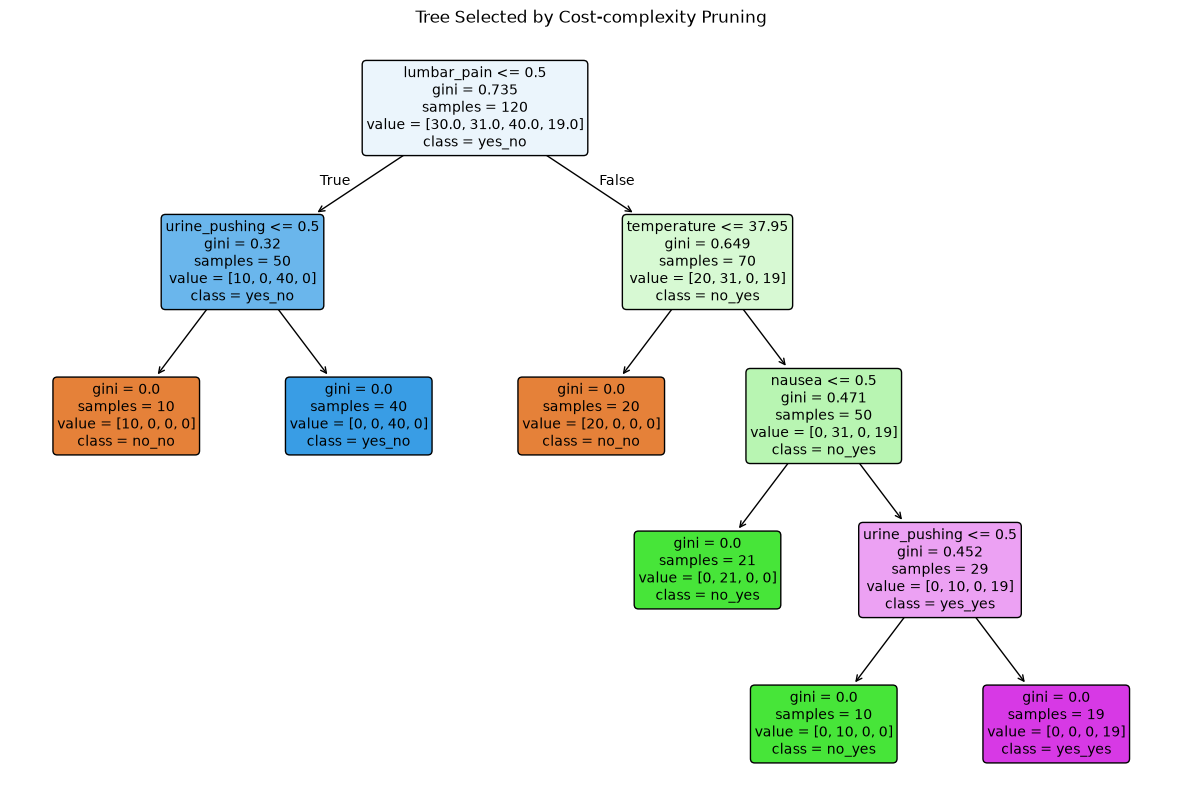

IF lumbar_pain <= 0.50 THEN
 IF urine_pushing <= 0.50 THEN
  RETURN no_no
 ELSE
  RETURN yes_no
ELSE
 IF temperature <= 37.95 THEN
  RETURN no_no
 ELSE
  IF nausea <= 0.50 THEN
   RETURN no_yes
  ELSE
   IF urine_pushing <= 0.50 THEN
    RETURN no_yes
   ELSE
    RETURN yes_yes


In [6]:
pruned_tree = DecisionTreeClassifier(random_state = 42, ccp_alpha = best_alpha)
pruned_tree.fit(X, y)

plt.figure(figsize = (15, 10))
plot_tree(pruned_tree, feature_names = X.columns.tolist(), class_names = pruned_tree.classes_.tolist(), filled = True, rounded = True)
plt.title("Tree Selected by Cost-complexity Pruning")
plt.show()

tree_to_pseudo(pruned_tree, X.columns.tolist())

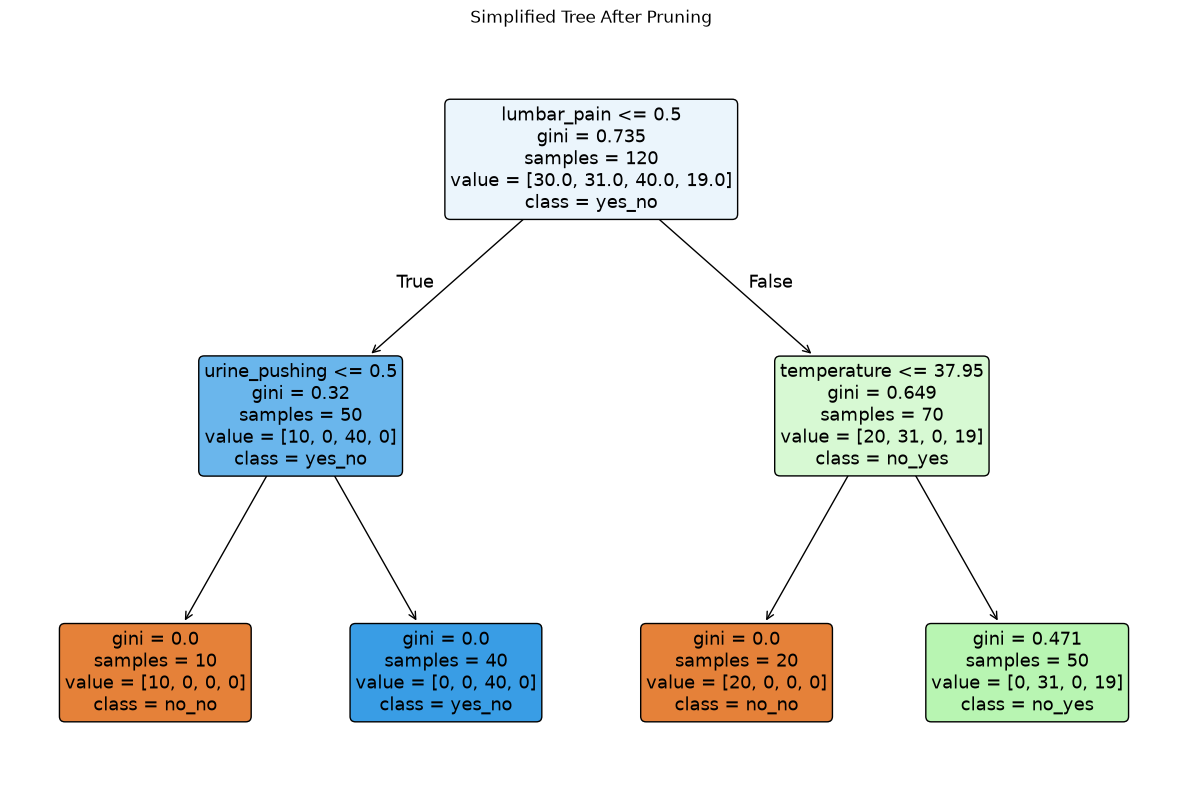

IF lumbar_pain <= 0.50 THEN
 IF urine_pushing <= 0.50 THEN
  RETURN no_no
 ELSE
  RETURN yes_no
ELSE
 IF temperature <= 37.95 THEN
  RETURN no_no
 ELSE
  RETURN no_yes


In [7]:
simple_alpha = pruning_results.loc[1, "alpha"]

simple_tree = DecisionTreeClassifier(random_state = 42, ccp_alpha = simple_alpha)
simple_tree.fit(X, y)

plt.figure(figsize = (15, 10))
plot_tree(simple_tree, feature_names = X.columns.tolist(), class_names = simple_tree.classes_.tolist(), filled = True, rounded = True)
plt.title("Simplified Tree After Pruning")
plt.show()

tree_to_pseudo(simple_tree, X.columns.tolist())

Cross-validation selected alpha = 0 with 99.17% accuracy. Using alpha about 0.098 reduced the tree's leaves from 6 to 4 and depth from 4 to 2, but CV accuracy decreased to 85.83%, showing a trade-off between accuracy and interpretability.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [8]:
crime_data = pd.read_csv("communities.data", header = None, na_values = "?")

crime_train = crime_data.iloc[:1495].copy()
crime_test = crime_data.iloc[1495:].copy()

display(crime_data.head())
print("Training data:", crime_train.shape)
print("Test data:", crime_test.shape)

,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


Training data: (1495, 128)
Test data: (499, 128)


### (b) Missing values

In [9]:
X_train = crime_train.iloc[:, 5:-1].copy()
X_test = crime_test.iloc[:, 5:-1].copy()

y_train = crime_train.iloc[:, -1].copy()
y_test = crime_test.iloc[:, -1].copy()

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(imputer.fit_transform(X_train), columns = X_train.columns, index = X_train.index)

X_test = pd.DataFrame(imputer.transform(X_test), columns = X_test.columns, index = X_test.index)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training missing values:", X_train.isna().sum().sum())
print("Test missing values:", X_test.isna().sum().sum())

Training features: (1495, 122)
Test features: (499, 122)
Training missing values: 0
Test missing values: 0


### (c) Plot a correlation matrix

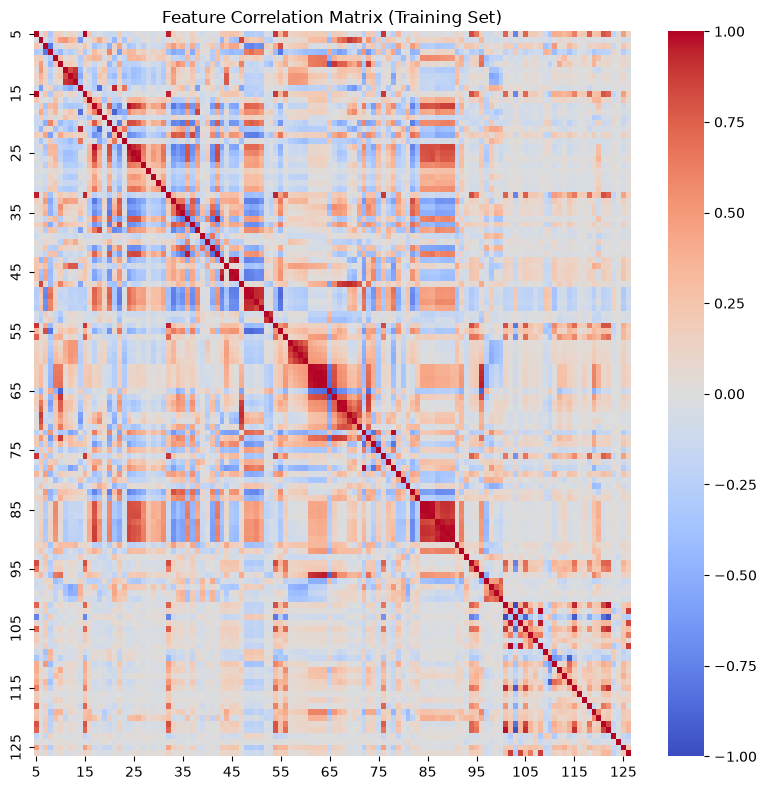

In [10]:
plt.figure(figsize=(8, 8))
sns.heatmap(X_train.corr(), cmap = "coolwarm", vmin = -1, vmax = 1, center = 0, xticklabels = 10, yticklabels = 10)

plt.title("Feature Correlation Matrix (Training Set)")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [11]:
feature_cv = (X_train.std(ddof = 1) / X_train.mean().replace(0, np.nan))

cv_table = feature_cv.sort_values(ascending = False).to_frame(name = "CV")

display(cv_table)

,CV
113,5.527059
95,4.292923
94,3.470952
54,3.058964
56,2.926635
...,...
116,0.141021
109,0.129652
110,0.118727
123,0.112032


### (e) Scatter plots and box plots for highest CV features

,CV
113,5.527059
95,4.292923
94,3.470952
54,3.058964
56,2.926635
125,2.552946
32,2.342443
101,2.248042
5,2.241105
15,2.038461


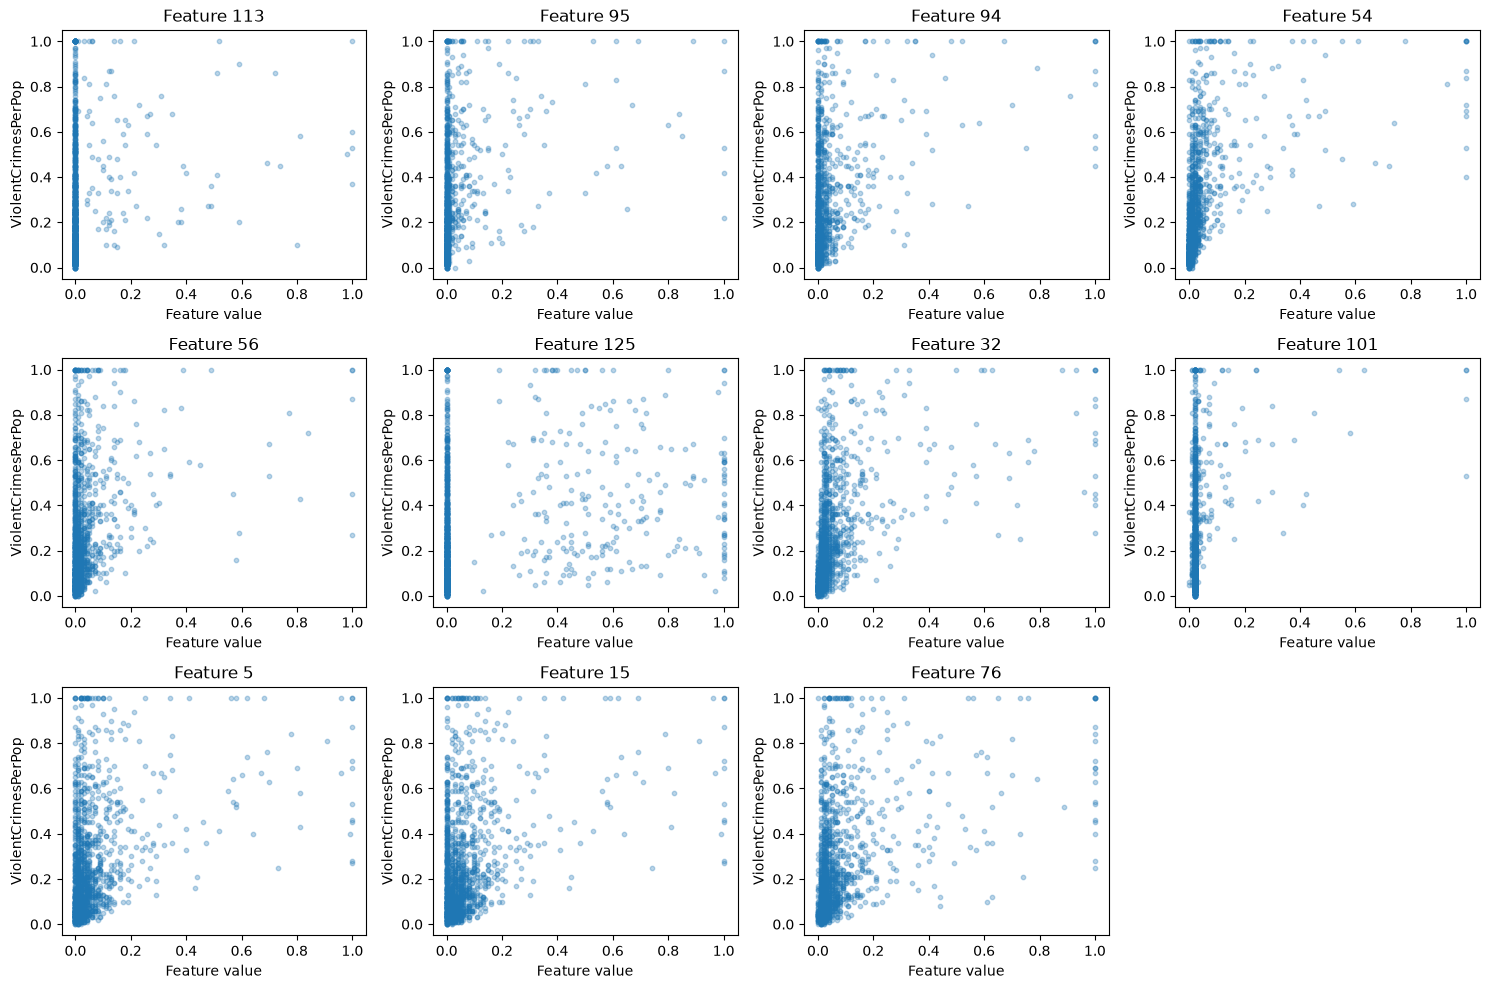

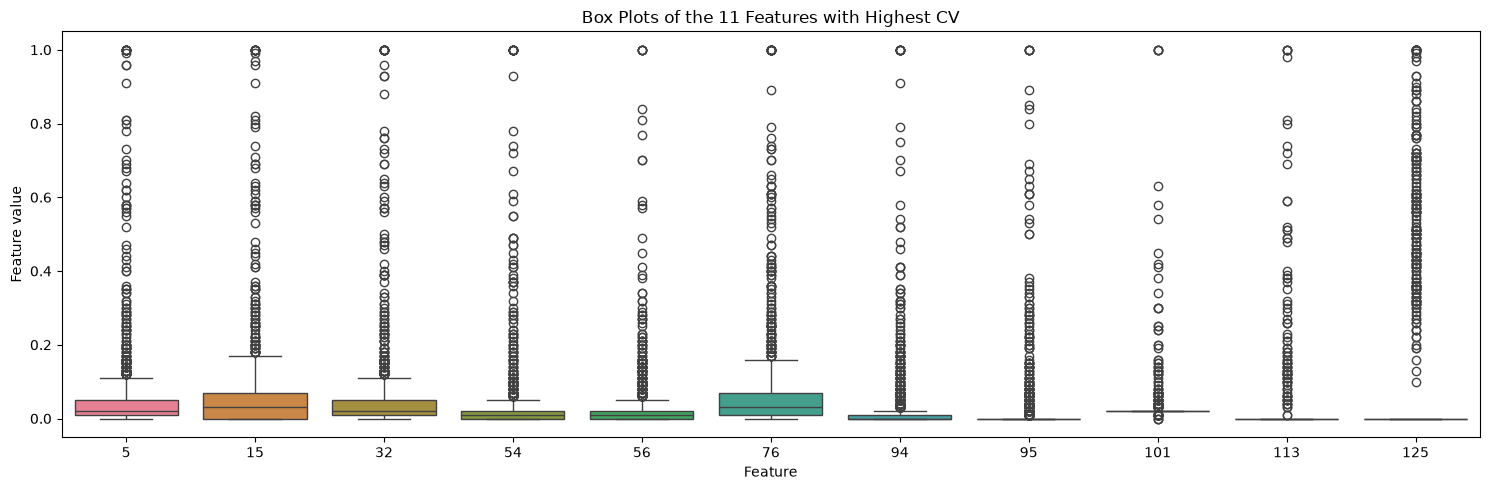

In [12]:
top_features = cv_table.head(11).index
display(cv_table.head(11))

fig, axes = plt.subplots(3, 4, figsize=(15, 10))

for ax, feature in zip(axes.flat, top_features):
    ax.scatter(X_train[feature], y_train, alpha = 0.3, s = 10)
    ax.set_title(f"Feature {feature}")
    ax.set_xlabel("Feature value")
    ax.set_ylabel("ViolentCrimesPerPop")

axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
sns.boxplot(data=X_train[top_features])

plt.xlabel("Feature")
plt.ylabel("Feature value")
plt.title("Box Plots of the 11 Features with Highest CV")
plt.tight_layout()
plt.show()

Scatter plots can suggest relationships between features and the response, but they cannot establish statistical significance. A high CV indicates greater relative variability, not necessarily greater predictive importance.

### (f) Fit a linear model

In [13]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)
linear_mse = mean_squared_error(y_test, linear_predictions)

print("Linear regression test MSE:", linear_mse)

Linear regression test MSE: 0.01796621542606732


### (g) Fit a ridge regression model

In [14]:
ridge_pipeline = make_pipeline(SimpleImputer(strategy = "median"),Ridge())

ridge_search = GridSearchCV(ridge_pipeline, param_grid = {"ridge__alpha": np.logspace(-4, 4, 50)}, scoring = "neg_mean_squared_error", cv = KFold(n_splits = 5, shuffle = True, random_state = 42))

ridge_search.fit(crime_train.iloc[:, 5 : -1], y_train)

ridge_predictions = ridge_search.predict(crime_test.iloc[:, 5:-1])
ridge_mse = mean_squared_error(y_test, ridge_predictions)

print("Best alpha:", ridge_search.best_params_["ridge__alpha"])
print("Ridge regression test MSE:", ridge_mse)

Best alpha: 3.727593720314938
Ridge regression test MSE: 0.017460906418438487


### (h) Fit a LASSO model

In [15]:
lasso_pipeline = make_pipeline(SimpleImputer(strategy = "median"), Lasso(max_iter = 100000))

lasso_search = GridSearchCV(lasso_pipeline, param_grid = {"lasso__alpha": np.logspace(-5, -1, 50)}, scoring = "neg_mean_squared_error", cv = KFold(n_splits = 5, shuffle = True, random_state = 42))
lasso_search.fit(crime_train.iloc[:, 5 : -1], y_train)

lasso_predictions = lasso_search.predict(crime_test.iloc[:, 5 : -1])
lasso_mse = mean_squared_error(y_test, lasso_predictions)
lasso_coefficients = pd.Series(lasso_search.best_estimator_.named_steps["lasso"].coef_, index = X_train.columns)
selected_features = lasso_coefficients[lasso_coefficients != 0]

print("Best alpha:", lasso_search.best_params_["lasso__alpha"])
print("LASSO test MSE:", lasso_mse)
print("Number of selected features:", len(selected_features))
display(selected_features.to_frame(name="Coefficient"))

Best alpha: 0.00011513953993264469
LASSO test MSE: 0.017635883463934236
Number of selected features: 74


,Coefficient
7,0.268041
9,-0.015471
11,0.066036
12,-0.265907
16,0.040825
...,...
119,0.011559
120,-0.043794
121,0.019868
123,0.014573


In [16]:
scaled_lasso_pipeline = make_pipeline(SimpleImputer(strategy = "median"), StandardScaler(), Lasso(max_iter = 100000))

scaled_lasso_search = GridSearchCV(scaled_lasso_pipeline, param_grid = {"lasso__alpha": np.logspace(-5, -1, 50)}, scoring = "neg_mean_squared_error", cv = KFold(n_splits = 5, shuffle = True, random_state = 42))

scaled_lasso_search.fit(crime_train.iloc[:, 5 : -1], y_train)

scaled_lasso_predictions = scaled_lasso_search.predict(crime_test.iloc[:, 5 : -1])
scaled_lasso_mse = mean_squared_error(y_test, scaled_lasso_predictions)

scaled_lasso_coefficients = pd.Series(scaled_lasso_search.best_estimator_.named_steps["lasso"].coef_, index = X_train.columns)

scaled_selected_features = scaled_lasso_coefficients[scaled_lasso_coefficients != 0]

print("Best alpha:", scaled_lasso_search.best_params_["lasso__alpha"])
print("Standardized LASSO test MSE:", scaled_lasso_mse)
print("Number of selected features:", len(scaled_selected_features))

print("Selected features:", selected_features.index.tolist())
print("Standardized selected features:",scaled_selected_features.index.tolist())

Best alpha: 0.0006250551925273969
Standardized LASSO test MSE: 0.017724903862373898
Number of selected features: 76
Selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 57, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 104, 107, 109, 111, 112, 113, 116, 117, 118, 119, 120, 121, 123, 124]
Standardized selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 57, 60, 64, 66, 68, 69, 70, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]


Feature numbers refer to the original dataset’s zero-based column indices.

LASSO without additional standardization selected 74 features with a test MSE of 0.0176. Standardized LASSO selected 76 features with a test MSE of 0.0177. Thus, standardization did not improve test performance in this experiment.

### (i) Fit a PCR model

In [17]:
pcr_pipeline = make_pipeline(SimpleImputer(strategy = "median"), StandardScaler(), PCA(svd_solver = "full"), LinearRegression())

pcr_search = GridSearchCV(pcr_pipeline, param_grid = {"pca__n_components": range(1, 123)}, scoring = "neg_mean_squared_error", cv = KFold(n_splits = 5, shuffle = True, random_state = 42))

pcr_search.fit(crime_train.iloc[:, 5 : -1], y_train)

pcr_predictions = pcr_search.predict(crime_test.iloc[:, 5 : -1])
pcr_mse = mean_squared_error(y_test, pcr_predictions)

print("Best M:", pcr_search.best_params_["pca__n_components"])
print("PCR test MSE:", pcr_mse)

Best M: 60
PCR test MSE: 0.018349525286169947


### (j) Fit a boosting tree

In [18]:
xgb_pipeline = make_pipeline(SimpleImputer(strategy = "median"), XGBRegressor(objective = "reg:squarederror", n_estimators = 500, max_depth = 3, learning_rate = 0.05, random_state = 42, n_jobs = 1))

xgb_search = GridSearchCV(xgb_pipeline, param_grid = { "xgbregressor__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]}, scoring = "neg_mean_squared_error", cv=KFold(n_splits = 5, shuffle = True, random_state = 42))

xgb_search.fit(crime_train.iloc[:, 5 : -1], y_train)

xgb_predictions = xgb_search.predict(crime_test.iloc[:, 5 : -1])
xgb_mse = mean_squared_error(y_test, xgb_predictions)

print("Best alpha:", xgb_search.best_params_["xgbregressor__reg_alpha"])
print("XGBoost test MSE:", xgb_mse)

Best alpha: 0.1
XGBoost test MSE: 0.016428752133415873
